# 01 · Simple-BEV → triplane (TPV), step by step

**`TRIPLANE_LIFTERS["simple_bev"]` → `lifting.triplane.SimpleBEVTriplaneLifter`**  ·  Harley et al., *Simple-BEV* (ICRA 2023) · `segnet.py`

> For every voxel: project its centre into every camera, bilinearly read the feature there, average over the cameras that see it - then collapse the volume along Z, Y and X.

This notebook shows, cell by cell, how the **Simple-BEV** lifting technique produces a
**tri-perspective view** (three orthogonal feature planes `xy` = BEV, `xz`, `yz`) instead of a single
bird's-eye-view map, *without changing a line of the existing BEV lifter* - the triplane module wraps it
(composition) and only adds what is needed to keep the height axis.

| § | what you will see |
|---|---|
| 1 | the idea, the animated step-by-step GIF and a detailed Mermaid diagram |
| 2 | every animation step as a still image |
| 3 | the shared toy scene (4 cameras, vehicles, pedestrians) |
| 4 | building the triplane lifter from the registry |
| 5 | **inside the lifter**: every intermediate tensor, with exact checks |
| 6 | the triplane contract, verified |
| 7 | end-to-end training on 3D semantic occupancy |
| 8 | the negative control: does it really use the cameras? |
| 9 | how to use it in your own code, recap, cheat sheet, exercises |

## 1. The idea

![Simple-BEV triplane lifting animation](../../assets/triplane/simple_bev.gif)


Simple-BEV showed that the simplest possible lifting works remarkably well: **no depth estimation and no attention**.
Each voxel centre `(x, y, z)` is projected into each camera with the calibration; the image feature at that pixel is
read bilinearly; the reads of all cameras that see the voxel are averaged. The result is a dense `(B, C, X, Y, Z)`
volume in which a feature is *smeared along the whole camera ray* (every voxel on the ray reads the same pixel) - the
network learns to resolve depth later from multiple views and context.

The BEV lifter then folds `Z` into channels to get a BEV map. **The triplane version keeps everything up to the
voxel volume** (`BilinearSamplingLifter.unproject`, unchanged and parameter-free) and replaces the single BEV
compressor by `VoxelToTriplane`, which collapses the same volume along `Z` (→ `xy`), `Y` (→ `xz`) and `X` (→ `yz`).
Because the volume is genuinely 3D, all three planes are geometrically grounded: a pixel high up in the image
lands in high voxels and therefore in the upper rows of `xz` / `yz`.

### Detailed diagram

Colours: <span style="color:#d48806">■ data</span> · <span style="color:#1f77b4">■ fixed geometry</span>
· <span style="color:#8e44ad">■ learned</span> · <span style="color:#2e8b57">■ reused from the existing BEV lifter</span>
· <span style="color:#c0392b">■ outputs</span>. (Mermaid renders in JupyterLab ≥ 4.1, VS Code and on GitHub;
the matplotlib version below renders everywhere.)

```mermaid
flowchart LR
  IMG["N camera images<br/>(B, N, 3, H, W)"]:::data --> ENC["ImageEncoder<br/>pyramid (B, N, C, H_l, W_l)"]:::learned
  CAM["Cameras<br/>K (B,N,3,3) · cam_to_ego (B,N,4,4)"]:::data
  subgraph CORE["BilinearSamplingLifter.unproject (existing, unchanged)"]
    direction TB
    VC["GridSpec.voxel_centers<br/>X·Y·Z metric points"]:::geo --> PRJ["Cameras.project<br/>(u, v), depth, valid"]:::geo
    PRJ --> SMP["sample_multi_camera<br/>bilinear read at (u, v)"]:::geo
    SMP --> AVG["masked_camera_mean<br/>average over cameras that see the voxel"]:::geo
  end
  ENC --> SMP
  CAM --> PRJ
  AVG --> VOX["voxel volume<br/>(B, C, X, Y, Z)<br/>no learned weights"]:::reused
  subgraph V2T["VoxelToTriplane (new)"]
    direction TB
    CXY["fold Z into channels<br/>HeightCompressor → xy"]:::learned
    CXZ["fold Y into channels<br/>HeightCompressor → xz"]:::learned
    CYZ["fold X into channels<br/>HeightCompressor → yz"]:::learned
  end
  VOX --> CXY & CXZ & CYZ
  CXY & CXZ & CYZ --> TPV
  TPV["TPVPlanes<br/>xy (B,C,X,Y) · xz (B,C,X,Z) · yz (B,C,Y,Z)"]:::out
  TPV --> BEVH["TriplaneBEVHead<br/>f = xy + xz + yz → fold Z<br/>BEV (B, C, X, Y)"]:::learned
  TPV --> AGG["TPVAggregator<br/>voxel logits (B,K,X,Y,Z)<br/>+ point logits (B,K,P)"]:::learned
  classDef data fill:#fff7e6,stroke:#d48806,color:#222
  classDef geo fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef learned fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef reused fill:#eaf7ea,stroke:#2e8b57,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

### Shapes and equations


For voxel centre $p = (x, y, z)$ and camera $n$ with intrinsics $K_n$ and ego→camera transform $(R_n, t_n)$:

$$ \tilde u = K_n (R_n p + t_n), \qquad (u, v) = (\tilde u_0 / \tilde u_2,\ \tilde u_1 / \tilde u_2), \qquad
V(p) = \frac{\sum_n m_n(p)\, \mathrm{bilinear}(F_n, u, v)}{\max(1, \sum_n m_n(p))} $$

where $m_n(p) = 1$ if the point is in front of camera $n$ and inside its image. Then

$$ xy = \mathrm{Conv}_{C\cdot Z \to C}(V),\quad xz = \mathrm{Conv}_{C\cdot Y \to C}(V^{\top}),\quad yz = \mathrm{Conv}_{C\cdot X \to C}(V^{\top\top}) $$

| tensor | shape |
|---|---|
| features (level 0) | `(B, N, C, H/4, W/4)` |
| voxel volume `V` | `(B, C, X, Y, Z)` |
| planes | `xy (B, C, X, Y)`, `xz (B, C, X, Z)`, `yz (B, C, Y, Z)` |

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")

# tpv_kit lives next to this notebook; also works when Jupyter starts at the repo root.
for _p in (".", os.path.join("notebooks", "triplane")):
    if os.path.isdir(os.path.join(_p, "tpv_kit")):
        sys.path.insert(0, os.path.abspath(_p)); break

import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt

from lifting import BaseLifter
from lifting.encoders import SimpleConvEncoder
from lifting.lifters import LIFTERS
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_lifter, build_triplane_model, build_triplane_bev_model
from tpv_kit import (TriplaneScene, PlanePlotter, PipelineDiagram, StoryboardViewer,
                     TriplaneContractChecker, OccupancyExperiment, ExperimentResult)

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 100, "image.interpolation": "nearest"})
plotter = PlanePlotter()
print("torch", torch.__version__, "| triplane lifters:", TRIPLANE_LIFTERS.names())

torch 2.14.1 | triplane lifters: ['alpamayo', 'bev_adapter', 'bevformer', 'depth_warp', 'lift_splat', 'mlp_view', 'simple_bev', 'tiim', 'tpvformer']


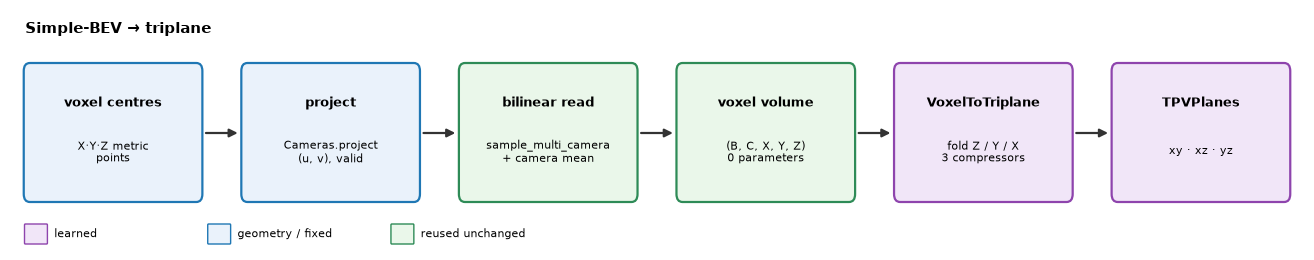

In [2]:
PipelineDiagram('Simple-BEV → triplane').extend([
    ('voxel centres', 'X·Y·Z metric\npoints', 'geometry'),
    ('project', 'Cameras.project\n(u, v), valid', 'geometry'),
    ('bilinear read', 'sample_multi_camera\n+ camera mean', 'reused'),
    ('voxel volume', '(B, C, X, Y, Z)\n0 parameters', 'reused'),
    ('VoxelToTriplane', 'fold Z / Y / X\n3 compressors', 'learned'),
    ('TPVPlanes', 'xy · xz · yz', 'learned'),
]).show()

## 2. The animation, one still per step

The GIF above is rendered by `lifting.triplane.animation` (Pillow only, exact geometry on a toy scene:
4 cameras at the origin, a car, a pedestrian and a pole). `StoryboardViewer` re-renders the **final frame of every
step** so the whole sequence can be read at once. Regenerate all GIFs with `python scripts/make_triplane_gifs.py`.

step 1: Inputs
step 2: Voxel centres
step 3: Project into every camera
step 4: Bilinear sample + camera average
step 5: Collapse Z, Y and X
step 6: Triplane output


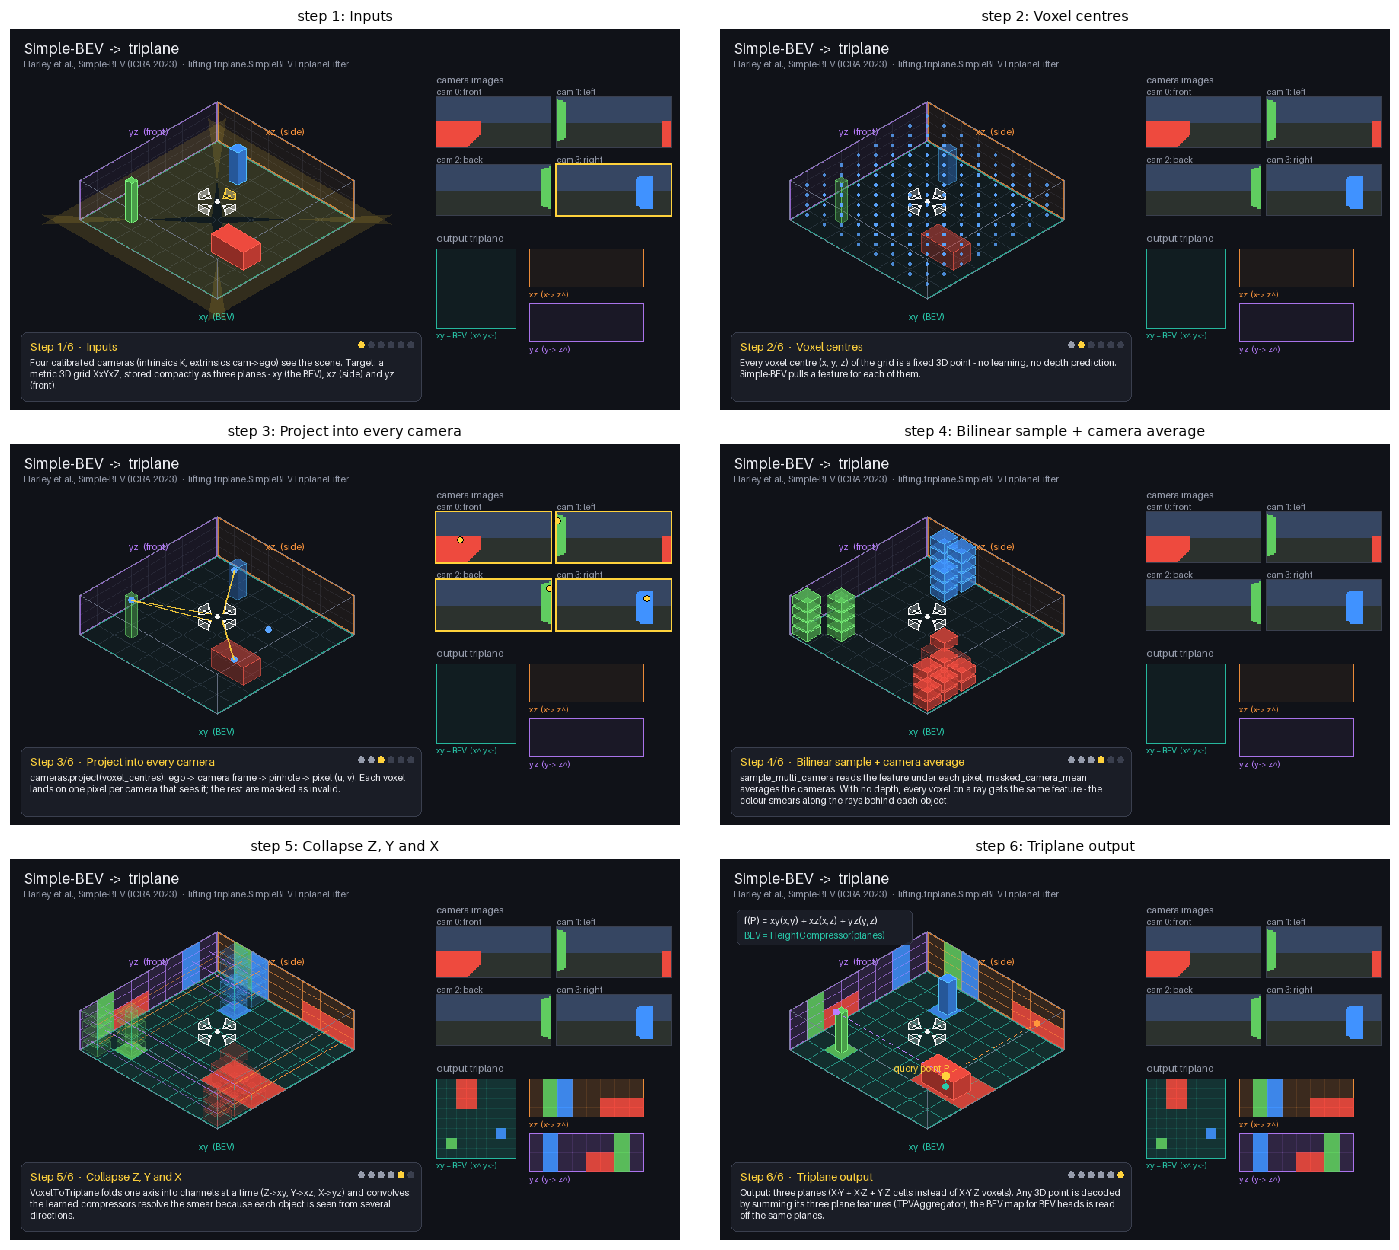

In [3]:
viewer = StoryboardViewer("simple_bev")
for i, title in enumerate(viewer.step_titles(), 1):
    print(f"step {i}: {title}")
viewer.contact_sheet()

## 3. The scene

Every triplane notebook uses the same `TriplaneScene`: a `32 m × 32 m × 4 m` region cut into `16 × 16 × 4`
cells, four `48 × 96` cameras whose yaw is **randomly rotated per scene** (so no network can memorise where
"front" is - it must read the calibration), and procedurally placed vehicles (red) and pedestrians (blue).
The ground truth is a 3D occupancy grid `(B, X, Y, Z)`; collapsing it along each axis gives the three
**label planes** each triplane is supervised against.

grid      : x (-16.0, 16.0) y (-16.0, 16.0) z (-1.0, 3.0) m, resolution (16, 16, 4)
voxel     : (2.0, 2.0, 1.0) m
cameras   : 4 x (48, 96) px
scenes    : 128 train / 32 test (batch 4)
TPV cells : xy 256 + xz 64 + yz 64 = 384  (voxels: 1024)


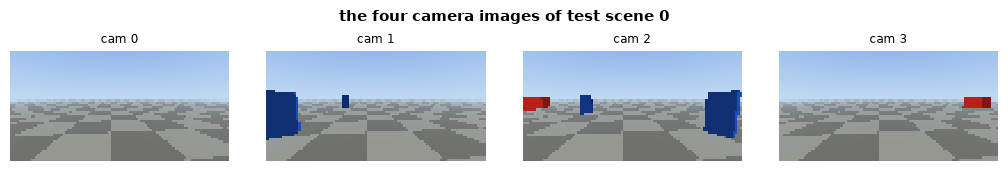

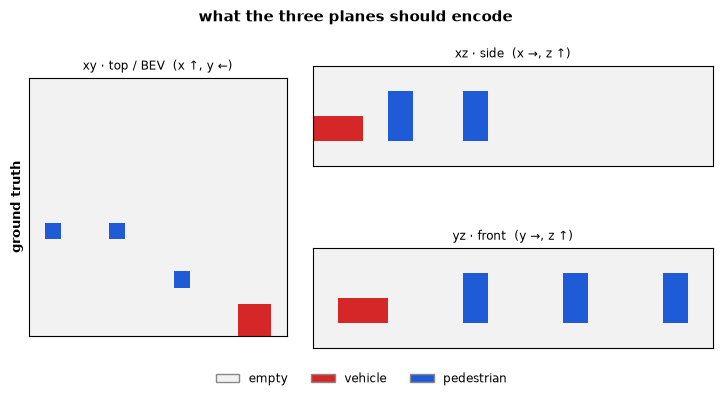

In [4]:
scene = TriplaneScene()
print(scene.describe())
batch = scene.sample
plotter.cameras(batch.images, title="the four camera images of test scene 0")
plotter.labels([("ground truth", scene.label_planes(batch.occupancy))], title="what the three planes should encode")

## 4. Build the triplane lifter

Two equivalent ways:

* `TRIPLANE_LIFTERS.build("simple_bev", grid=..., in_channels=..., out_channels=...)` - the raw registry;
* `build_triplane_lifter("simple_bev", grid, channels, image_size, num_cameras, encoder)` - also injects the
  context some lifters need (`feature_size`, `num_cameras`, `depth_bins`), exactly like `lifting.models.build_lifter`
  does for BEV lifters.

The image encoder turns `(B·N, 3, H, W)` images into a feature pyramid (strides 4 and 8 here); every lifter
consumes `(B, N, C, H_l, W_l)` per level.

In [5]:
C = 32
encoder = SimpleConvEncoder(out_channels=C, num_levels=2)
features = scene.encode(encoder, batch)
cameras = batch.cameras
print("feature pyramid:", [tuple(f.shape) for f in features])

lifter = build_triplane_lifter("simple_bev", scene.grid, C, scene.image_size, scene.num_cameras, encoder)
print(type(lifter).__name__, "| is a BaseLifter too:", isinstance(lifter, BaseLifter))
print(f"parameters: {sum(p.numel() for p in lifter.parameters()):,}")
for name, child in lifter.named_children():
    n = sum(p.numel() for p in child.parameters())
    print(f"  .{name:<12s} {type(child).__name__:<28s} {n:>9,} params")

feature pyramid: [(4, 4, 32, 12, 24), (4, 4, 32, 6, 12)]
SimpleBEVTriplaneLifter | is a BaseLifter too: True
parameters: 373,120
  .bev_head     TriplaneBEVHead                 37,984 params
  .core         BilinearSamplingLifter               0 params
  .to_planes    VoxelToTriplane                335,136 params


## 5. Inside the lifter, step by step

### 5.1 Project every voxel centre into every camera

`GridSpec.voxel_centers()` gives the metric centre of all `X·Y·Z` voxels; `Cameras.project` returns pixel coordinates,
depth and a validity mask (in front of the camera *and* inside the image). The cameras sit at the origin, so voxels
close to the ego are seen by more cameras (overlapping fields of view) and those in blind spots by none.

uv (4, 4, 1024, 2) | fraction of voxels seen by >= 1 camera: 0.988


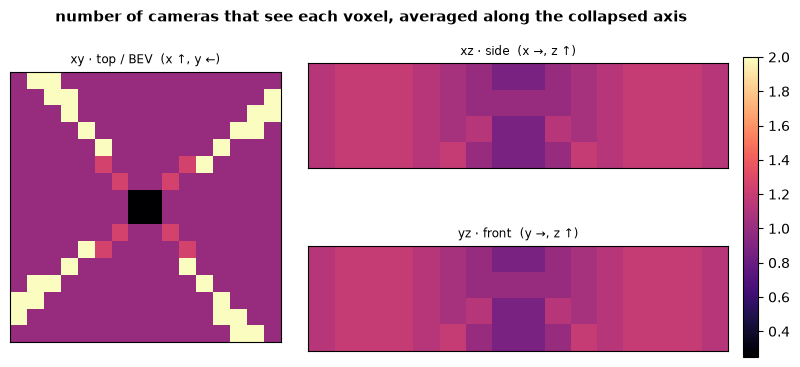

In [6]:
# How many cameras see every voxel centre? (the geometry every voxel-based lifter relies on)
pts = scene.grid.voxel_centers().view(1, -1, 3).expand(batch.images.shape[0], -1, -1)
uv, depth, valid = cameras.project(pts)                      # (B, N, X*Y*Z, 2), (B, N, P), (B, N, P)
seen = valid.sum(1)[0].view(*scene.grid.resolution).float() # cameras that see each voxel, scene 0
print("uv", tuple(uv.shape), "| fraction of voxels seen by >= 1 camera:", round((seen > 0).float().mean().item(), 3))
plotter.scalar_planes([seen.mean(2), seen.mean(1), seen.mean(0)],
                      "number of cameras that see each voxel, averaged along the collapsed axis", cmap="magma")

### 5.2 Unproject: one bilinear read per (voxel, camera), averaged

`lifter.lift_voxels` calls the **unchanged** `BilinearSamplingLifter.unproject`. It has no parameters - the cell below
re-computes one voxel by hand with `F.grid_sample` and checks the library gets exactly the same number.

In [7]:
voxels = lifter.lift_voxels(features, cameras)        # (B, C, X, Y, Z)
print("voxel volume:", tuple(voxels.shape), "| parameters used:", sum(p.numel() for p in lifter.core.parameters()))

# pick a voxel seen by exactly one camera in scene 0 and recompute it by hand
flat_valid = valid[0]                                  # (N, P)
p_idx = int(torch.nonzero(flat_valid.sum(0) == 1)[0])
cam = int(torch.nonzero(flat_valid[:, p_idx])[0])
f0 = features[lifter.level][0, cam]                    # (C, h, w)
uvn = cameras.normalize_uv(uv)[0, cam, p_idx]          # [0, 1]
by_hand = F.grid_sample(f0[None], (2 * uvn - 1).view(1, 1, 1, 2), align_corners=False).view(-1)
lib = voxels[0].flatten(1)[:, p_idx]
print(f"voxel #{p_idx} seen only by camera {cam} at pixel {uv[0, cam, p_idx].tolist()}")
print("max |by hand - library| =", (by_hand - lib).abs().max().item())

voxel volume: (4, 32, 16, 16, 4) | parameters used: 0
voxel #0 seen only by camera 3 at pixel [80.37950897216797, 24.886545181274414]
max |by hand - library| = 0.0


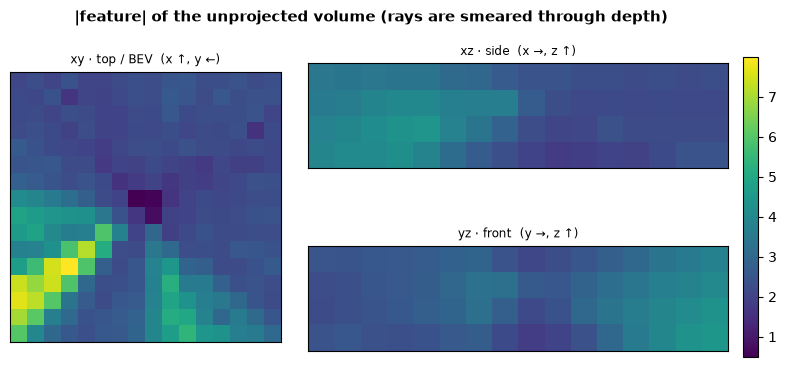

In [8]:
# A pixel's feature is copied to EVERY voxel along its camera ray: look at the feature norm of the volume
norm = voxels[0].norm(dim=0)                           # (X, Y, Z)
plotter.scalar_planes([norm.mean(2), norm.mean(1), norm.mean(0)],
                      "|feature| of the unprojected volume (rays are smeared through depth)")

### Collapse the volume into three planes: `VoxelToTriplane`

A BEV lifter ends with a `HeightCompressor`: fold `Z` into the channels (`C·Z`) and convolve over `(X, Y)`.
`VoxelToTriplane` does that **three times**, each time moving a different axis to the end:

| plane | permute `(B, C, X, Y, Z)` → | folded axis | conv over |
|---|---|---|---|
| `xy` | `(B, C, X, Y, Z)` | `Z` | `(X, Y)` |
| `xz` | `(B, C, X, Z, Y)` | `Y` | `(X, Z)` |
| `yz` | `(B, C, Y, Z, X)` | `X` | `(Y, Z)` |

**Why fold rather than average?** Folding keeps *where along the collapsed axis* a feature was: the `xz` plane
can still tell a car on the left from one on the right. The next cell proves it on a toy volume.

In [9]:
from lifting.triplane import VoxelToTriplane
from lifting.geometry import GridSpec

tiny = GridSpec(resolution=(2, 3, 2))
to_planes = VoxelToTriplane(in_channels=1, grid=tiny, out_channels=4).eval()
a = torch.zeros(1, 1, 2, 3, 2); a[..., 0, 0, 1] = 1.0      # feature at y = 0 (left)
b = torch.zeros(1, 1, 2, 3, 2); b[..., 0, 2, 1] = 1.0      # same feature at y = 2 (right)
with torch.no_grad():
    pa, pb = to_planes(a), to_planes(b)
print("mean over Y identical?      ", torch.equal(a.mean(3), b.mean(3)), "  <- averaging would lose left vs right")
print("folded xz planes identical? ", torch.allclose(pa.xz, pb.xz), " <- VoxelToTriplane keeps it")
print("compressor weights (C_in·folded axis -> C_out):",
      {k: tuple(m.weight.shape) for k, m in to_planes.named_modules() if isinstance(m, torch.nn.Conv2d)})

mean over Y identical?       True   <- averaging would lose left vs right
folded xz planes identical?  False  <- VoxelToTriplane keeps it
compressor weights (C_in·folded axis -> C_out): {'compress_xy.conv.0.0': (4, 2, 3, 3), 'compress_xy.conv.1': (4, 4, 1, 1), 'compress_xz.conv.0.0': (4, 3, 3, 3), 'compress_xz.conv.1': (4, 4, 1, 1), 'compress_yz.conv.0.0': (4, 2, 3, 3), 'compress_yz.conv.1': (4, 4, 1, 1)}


In [10]:
voxels = lifter.lift_voxels(features, cameras)
planes = lifter.to_planes(voxels)
print("voxels", tuple(voxels.shape), "->", {k: tuple(getattr(planes, k).shape) for k in ("xy", "xz", "yz")})
print(f"memory: voxels {voxels[0].numel():,} floats per scene vs planes "
      f"{sum(getattr(planes, k)[0].numel() for k in ('xy', 'xz', 'yz')):,}")

voxels (4, 32, 16, 16, 4) -> {'xy': (4, 32, 16, 16), 'xz': (4, 32, 16, 4), 'yz': (4, 32, 16, 4)}
memory: voxels 32,768 floats per scene vs planes 12,288


## 6. The triplane contract, verified

Every triplane lifter promises the same five properties (Liskov: it is still a `BaseLifter`, so it drops into
`BEVSegmentationModel`, the trainer and the verifier unchanged). `TriplaneContractChecker` runs them on real tensors.

PASS  plane shapes            xy(4, 32, 16, 16) xz(4, 32, 16, 4) yz(4, 32, 16, 4)
PASS  BEV = bev_head(planes)  BEV (4, 32, 16, 16), max |diff| = 0.0e+00
PASS  f = xy + xz + yz        voxel (8,8,2) max |diff| = 0.0e+00
PASS  reuses BEV lifter       core = BilinearSamplingLifter = LIFTERS['simple_bev']
PASS  gradients reach images  1/2 pyramid levels receive gradient


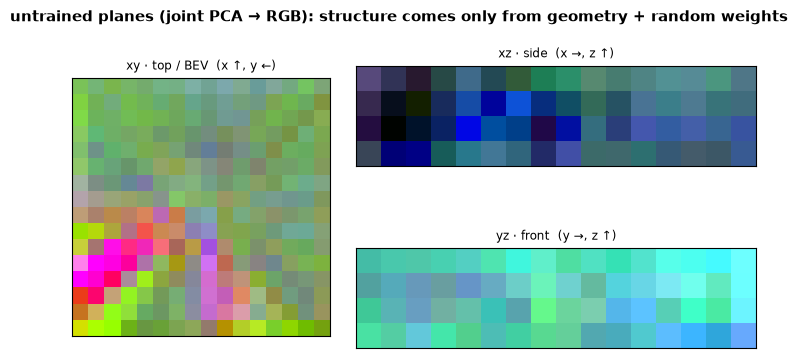

In [11]:
assert TriplaneContractChecker(lifter, features, cameras).run()
with torch.no_grad():
    planes = lifter.lift_planes(features, cameras)
plotter.features(planes, title="untrained planes (joint PCA → RGB): structure comes only from geometry + random weights")

## 7. Train end to end on 3D semantic occupancy

`build_triplane_model("simple_bev", ...)` = encoder → **this triplane lifter** → `TPVAggregator` (an MLP on
`f(x,y,z) = xy + xz + yz`), plus one auxiliary classifier per plane. `OccupancyTask(aux_weight=0.5)` adds a
cross-entropy on each plane against the collapsed labels of §3. 150 AdamW steps on 128 scenes, CPU only.

lifter          params    time   before    after  corrupted   verdict
simple_bev        510k    4.5s    0.000    0.375      0.030   uses geometry


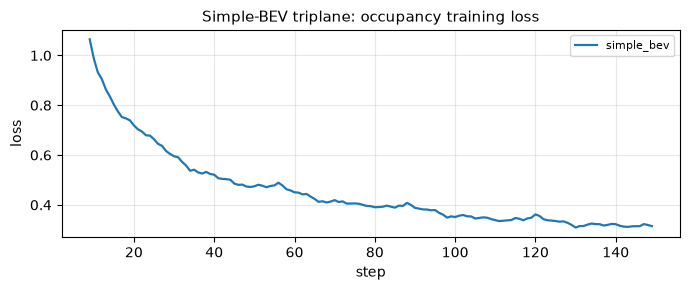

In [12]:
exp = OccupancyExperiment(scene, "simple_bev")
result = exp.run(steps=150)
print(ExperimentResult.header()); print(result.row())
OccupancyExperiment.plot_losses([result], title="Simple-BEV triplane: occupancy training loss")

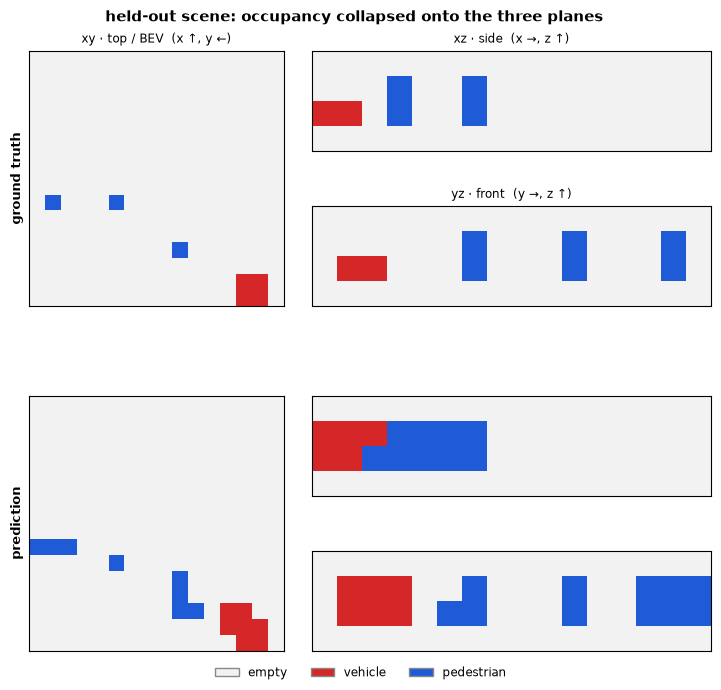

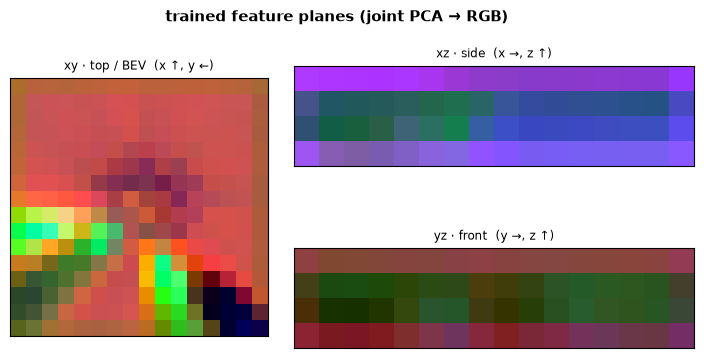

In [13]:
out = exp.predict()
pred = out["voxel_logits"].argmax(1)                       # (B, X, Y, Z) class ids
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("prediction", scene.label_planes(pred))],
               title="held-out scene: occupancy collapsed onto the three planes")
plotter.features(out["planes"], title="trained feature planes (joint PCA → RGB)")

## 8. Negative control: does it really use the cameras?

Same images, same weights - but every camera's extrinsic is rotated by 90° about the vertical axis. A lifter that reads
pixels **through** the calibration now puts every object in the wrong place and its mIoU collapses; a geometry-free
lifter would not notice. (This is the triplane version of the repo's `lifting-verify` check.)

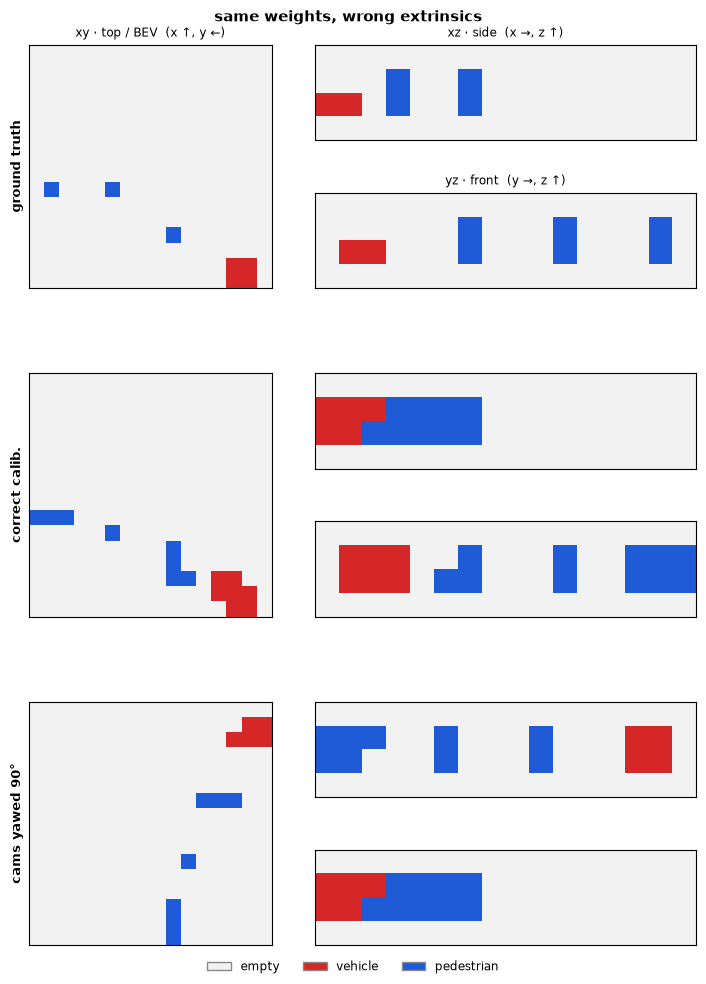

mIoU  correct calibration: 0.375   |   cameras yawed 90°: 0.030   ->  uses geometry ✅


In [14]:
corrupted = exp.predict(corrupted=True)["voxel_logits"].argmax(1)
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("correct calib.", scene.label_planes(pred)),
                ("cams yawed 90°", scene.label_planes(corrupted))],
               title="same weights, wrong extrinsics")
print(f"mIoU  correct calibration: {result.miou_after:.3f}   |   cameras yawed 90°: {result.miou_corrupted:.3f}"
      f"   ->  {'uses geometry ✅' if result.uses_geometry else 'does NOT use geometry'}")

## 9. Use it in your own code

```python
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_model, build_triplane_bev_model

# 1) just the lifter: features (B, N, C, H_l, W_l) per level + Cameras
lifter = TRIPLANE_LIFTERS.build("simple_bev", grid=grid, in_channels=64, out_channels=64)
planes = lifter.lift_planes(features, cameras)   # TPVPlanes(xy, xz, yz)
bev    = lifter(features, cameras)               # (B, 64, X, Y) - drop-in BEV lifter

# 2) 3D semantic occupancy + point queries
model = build_triplane_model("simple_bev", grid, num_classes=3, aux_heads=True)
out = model(images, cameras, points=lidar_xyz)   # planes, voxel_logits, point_logits, aux_logits

# 3) BEV segmentation read off the triplane (same API as lifting.build_bev_model)
bev_model = build_triplane_bev_model("simple_bev", grid, num_classes=3)
```

In [15]:
bev_model = build_triplane_bev_model("simple_bev", scene.grid, 3, scene.image_size, scene.num_cameras, channels=16)
with torch.no_grad():
    logits = bev_model(batch.images, batch.cameras)["logits"]
print("BEV segmentation logits read off the triplane:", tuple(logits.shape))

BEV segmentation logits read off the triplane: (4, 3, 16, 16)


## Recap


* Simple-BEV lifting is **parameter-free**: project, read, average. The triplane version reuses it verbatim.
* `VoxelToTriplane` turns the one BEV compressor into three axis compressors - this is the only new learned part.
* The planes are geometrically grounded on all three axes because the intermediate volume is truly 3D.


**Cheat sheet**

| concept | file |
|---|---|
| voxel unprojection (unchanged) | `src/lifting/lifters/bilinear_sampling_lifter.py` |
| camera sampling ops | `src/lifting/ops/camera_sampling.py` |
| triplane lifter | `src/lifting/triplane/simple_bev_triplane.py` |
| axis collapses | `src/lifting/triplane/plane_compressor.py` |
| triplane contract | `src/lifting/triplane/base.py` |
| BEV read-off from planes | `src/lifting/triplane/triplane_bev_head.py` |
| occupancy model / factories | `src/lifting/triplane/triplane_occupancy_model.py`, `factory.py` |
| this animation | `src/lifting/triplane/animation/storyboards/simple_bev_storyboard.py` |

**Exercises**

1. Lift from the coarser pyramid level (`level=1`). How do the planes and the mIoU change?
2. Replace `masked_camera_mean` by a max over cameras (subclass the lifter). Does it help in overlap regions?
3. Increase `Z` to 8 cells (`TriplaneScene(resolution=(16, 16, 8))`). Which plane benefits most?

Next: see `00_triplane_overview.ipynb` for all techniques side by side.